In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers,models
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

In [6]:
# load dataset

digits  = load_digits()

x = digits.images
y = digits.target

In [11]:
print(f'x shape : {x.shape} \ny shape : {y.shape}')
print(f'\nTotal Image : {len(x)} \nunique classes : {np.unique(y)}')

x shape : (1797, 8, 8) 
y shape : (1797,)

Total Image : 1797 
unique classes : [0 1 2 3 4 5 6 7 8 9]


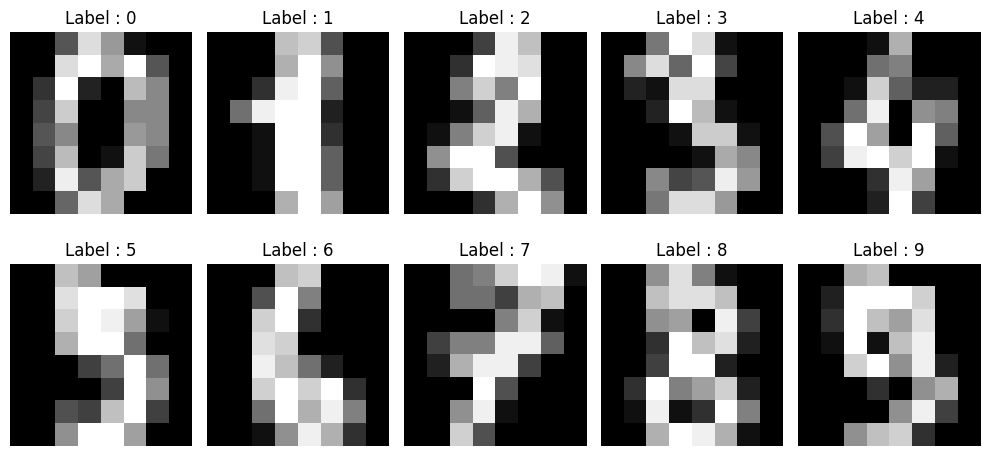

In [12]:
# visualize image

plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x[i], cmap='gray')
    plt.title(f"Label : {y[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# preprocessing
x = x/16.0
x = x.reshape(-1,8,8,1)

In [14]:
x_train,x_test,y_train,y_test = train_test_split(x,y,
                                                test_size=0.2,
                                                random_state=42,
                                                stratify=y)

In [17]:
# Build cnn architecture

model = models.Sequential([
    layers.Input(shape=(8,8,1)),
    layers.Conv2D(32,(3,3), activation='relu'),     # convolution layer
    layers.MaxPooling2D((2,2)),                     # Pooling layer
    layers.Flatten(),                               # Flatten layer
    layers.Dense(64, activation='relu'),            # fully connected layer
    layers.Dense(10, activation='softmax')
])

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 6, 6, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,466 (76.04 KB)

 Trainable params: 19,466 (76.04 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [20]:
# train model

history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.4247 - loss: 2.1485 - val_accuracy: 0.6285 - val_loss: 1.9330
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8007 - loss: 1.5540 - val_accuracy: 0.7882 - val_loss: 1.1826
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8869 - loss: 0.8165 - val_accuracy: 0.8819 - val_loss: 0.6159
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9173 - loss: 0.4556 - val_accuracy: 0.8889 - val_loss: 0.4209
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9382 - loss: 0.3154 - val_accuracy: 0.9306 - val_loss: 0.2995
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9452 - loss: 0.2491 - val_accuracy: 0.9306 - val_loss: 0.2745
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9530 - loss: 0.2039 - val_accuracy: 0.9410 - val_loss: 0.2363
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9626 - loss: 0.1698 - val_accuracy: 0.9271 - val_los

In [21]:
loss, accuracy = model.evaluate(x_test, y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9722 - loss: 0.1008  


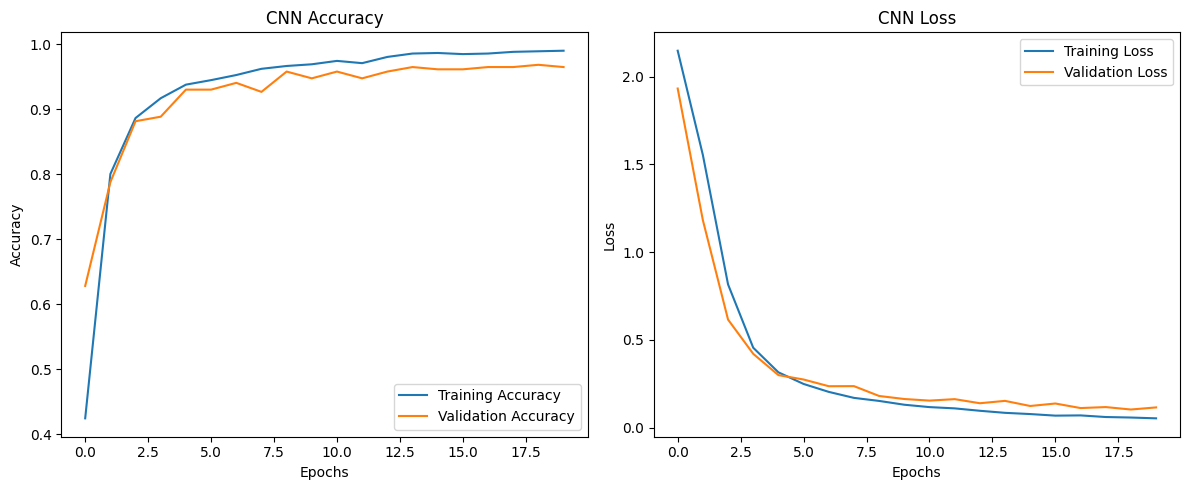

In [22]:
plt.figure(figsize=(12, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
predictions = model.predict(x_test[:10])

predicted_classes = np.argmax(predictions, axis=1)

print("Predicted:", predicted_classes)
print("Actual:   ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Predicted: [5 2 8 1 7 2 6 2 6 5]
Actual:    [5 2 8 1 7 2 6 2 6 5]


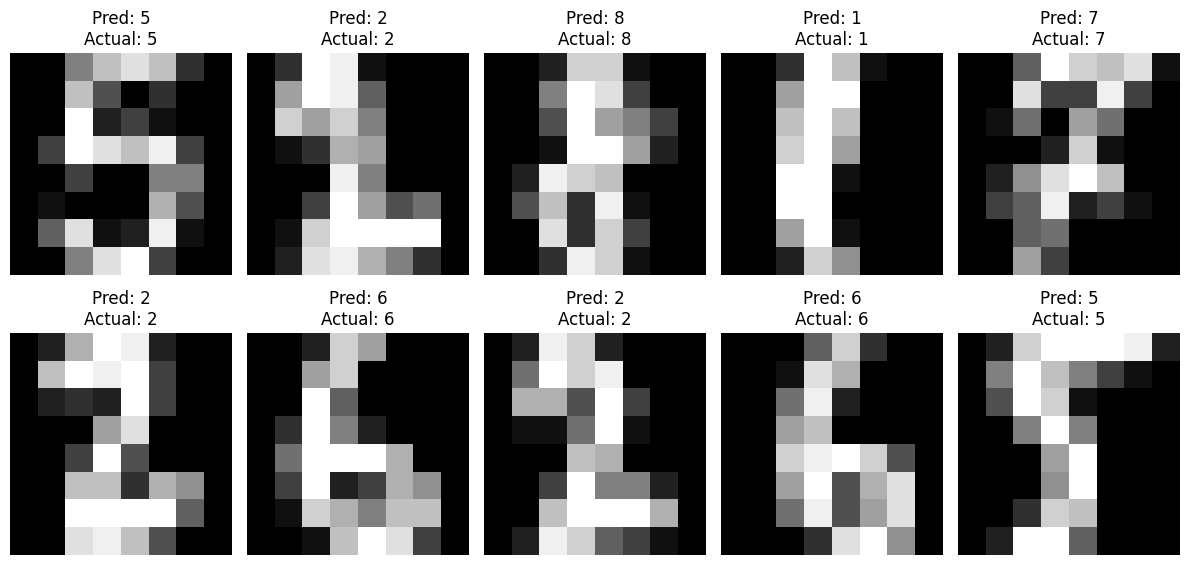

In [26]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i+1)

    plt.imshow(x_test[i].reshape(8, 8), cmap='gray')

    predicted = predicted_classes[i]
    actual = y_test[i]

    plt.title(
        f"Pred: {predicted}\nActual: {actual}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  


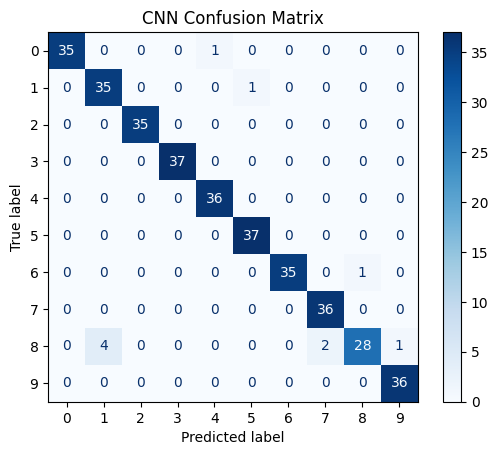

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(cmap='Blues')
plt.title("CNN Confusion Matrix")
plt.show()

In [29]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_classes
    )
)

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.90      0.97      0.93        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.95      1.00      0.97        36
           8       0.97      0.80      0.88        35
           9       0.97      1.00      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

